**Decision Tree Classifier**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
import pandas as pd
path='/content/drive/My Drive/ML Lab/Exp04/weather_classification_data.csv'
df=pd.read_csv(path)
print(df)

       Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0             14.0        73         9.5               82.0  partly cloudy   
1             39.0        96         8.5               71.0  partly cloudy   
2             30.0        64         7.0               16.0          clear   
3             38.0        83         1.5               82.0          clear   
4             27.0        74        17.0               66.0       overcast   
...            ...       ...         ...                ...            ...   
13195         10.0        74        14.5               71.0       overcast   
13196         -1.0        76         3.5               23.0         cloudy   
13197         30.0        77         5.5               28.0       overcast   
13198          3.0        76        10.0               94.0       overcast   
13199         -5.0        38         0.0               92.0       overcast   

       Atmospheric Pressure  UV Index  Season  Visibility (km) 

In [16]:
from sklearn.preprocessing import OneHotEncoder
y = df['Weather Type']
# Remove target from features
df = df.drop(columns=['Weather Type'])
col = 'Humidity'
df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
col = 'Precipitation (%)'
df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
col = 'Atmospheric Pressure'
df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
col = 'Temperature'
df[col] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())
encoder=OneHotEncoder(sparse_output=False)
encoded=encoder.fit_transform(df[['Cloud Cover','Season','Location']])
encoded_df=pd.DataFrame(
    encoded,
    columns=encoder.get_feature_names_out(['Cloud Cover','Season','Location'])
)
# Remove original categorical columns
df = df.drop(columns=['Cloud Cover','Season','Location'])
# Add encoded columns to existing df
df = pd.concat([df, encoded_df], axis=1)
print(df)

       Temperature  Humidity  Wind Speed  Precipitation (%)  \
0         0.291045  0.595506         9.5           0.752294   
1         0.477612  0.853933         8.5           0.651376   
2         0.410448  0.494382         7.0           0.146789   
3         0.470149  0.707865         1.5           0.752294   
4         0.388060  0.606742        17.0           0.605505   
...            ...       ...         ...                ...   
13195     0.261194  0.606742        14.5           0.651376   
13196     0.179104  0.629213         3.5           0.211009   
13197     0.410448  0.640449         5.5           0.256881   
13198     0.208955  0.629213        10.0           0.862385   
13199     0.149254  0.202247         0.0           0.844037   

       Atmospheric Pressure  UV Index  Visibility (km)  Cloud Cover_clear  \
0                  0.527951         2              3.5                0.0   
1                  0.529480         7             10.0                0.0   
2           

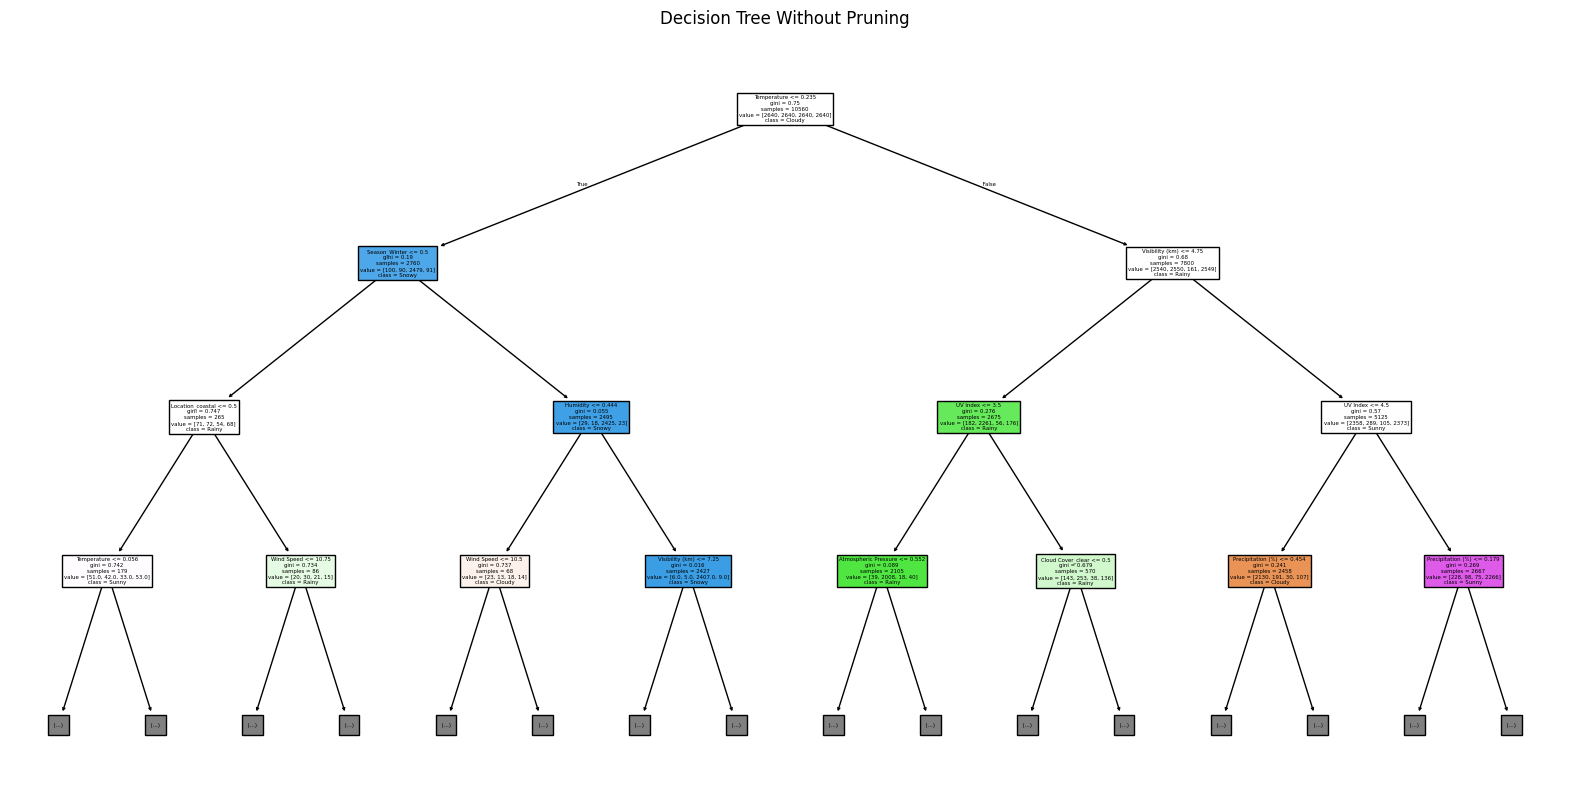

Accuracy without pruning: 0.9102272727272728
Accuracy with pruning: 0.8984848484848484

Without Pruning:
              precision    recall  f1-score   support

      Cloudy       0.90      0.90      0.90       660
       Rainy       0.90      0.90      0.90       660
       Snowy       0.94      0.92      0.93       660
       Sunny       0.91      0.92      0.92       660

    accuracy                           0.91      2640
   macro avg       0.91      0.91      0.91      2640
weighted avg       0.91      0.91      0.91      2640


With Pruning:
              precision    recall  f1-score   support

      Cloudy       0.85      0.90      0.87       660
       Rainy       0.90      0.90      0.90       660
       Snowy       0.95      0.91      0.93       660
       Sunny       0.90      0.89      0.89       660

    accuracy                           0.90      2640
   macro avg       0.90      0.90      0.90      2640
weighted avg       0.90      0.90      0.90      2640


Feature I

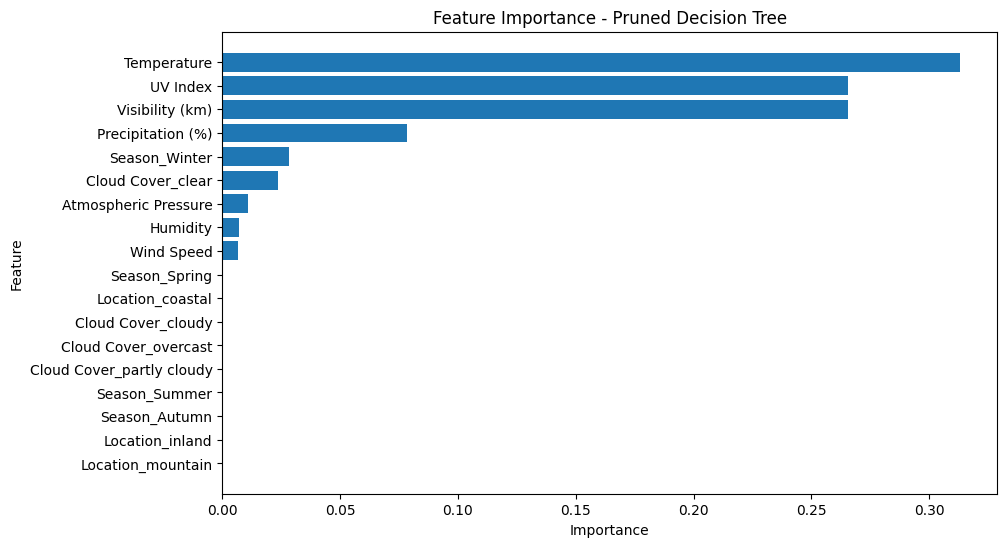

In [18]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
X_train, X_test, y_train, y_test = train_test_split(
    df, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# 4. Decision Tree WITHOUT Pruning
dt_unpruned = DecisionTreeClassifier(random_state=42)
dt_unpruned.fit(X_train, y_train)

# Prediction
y_pred_unpruned = dt_unpruned.predict(X_test)

# 5. Visualize Tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_unpruned,
    feature_names=X_train.columns,
    class_names=dt_unpruned.classes_,
    filled=True,
    max_depth=3
)
plt.title("Decision Tree Without Pruning")
plt.show()

# 6. Decision Tree WITH Pruning
dt_pruned = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)
dt_pruned.fit(X_train, y_train)

# Prediction
y_pred_pruned = dt_pruned.predict(X_test)

# 7. Compare Performance
accuracy_unpruned = accuracy_score(y_test, y_pred_unpruned)
accuracy_pruned = accuracy_score(y_test, y_pred_pruned)

print("Accuracy without pruning:", accuracy_unpruned)
print("Accuracy with pruning:", accuracy_pruned)

print("\nWithout Pruning:")
print(classification_report(y_test, y_pred_unpruned))

print("\nWith Pruning:")
print(classification_report(y_test, y_pred_pruned))

# 8. Feature Importance
importance = dt_pruned.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance)

# Feature Importance Graph
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Pruned Decision Tree")
plt.gca().invert_yaxis()
plt.show()